# TP IA explicable : prédiction de l'AVC
**Réalisé par :** Imane Guihia
**Module :** Explicabilité de l'IA
**Dataset :** Stroke Prediction Dataset (Kaggle)

In [1]:
!pip install shap lime -q


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", None)

In [3]:
import sklearn, xgboost, shap, matplotlib
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| shap", shap.__version__,
      "| matplotlib", matplotlib.__version__)

pandas 2.2.3 | scikit-learn 1.6.1 | xgboost 3.4.1 | shap 0.54.1 | matplotlib 3.10.0


# 1. Présentation du dataset

**Source :** Stroke Prediction Dataset (fedesoriano, Kaggle).

**Objectif :** prédire si un patient a eu un AVC (`stroke = 1`) à partir de ses caractéristiques démographiques, cliniques et de mode de vie.

**Contexte médical :** l'AVC est l'une des premières causes de décès et de handicap. Repérer les patients à risque permet la prévention (tension, glycémie, tabac). Le modèle doit être explicable pour qu'un médecin lui fasse confiance.

**Contenu :** 5 110 patients, 10 variables explicatives + 1 cible.


In [4]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
print(df.shape)
df.head()

(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


## Dictionnaire des variables

| Variable | Signification | Type |
|---|---|---|
| id | Identifiant patient | À supprimer |
| gender | Sexe (Male / Female / Other) | Catégorielle |
| age | Âge (années) | Numérique |
| hypertension | Hypertension (0/1) | Binaire |
| heart_disease | Maladie cardiaque (0/1) | Binaire |
| ever_married | Déjà marié (Yes/No) | Catégorielle binaire |
| work_type | Type d'emploi (Private, Self-employed, Govt_job, children, Never_worked) | Catégorielle ⚠️ |
| Residence_type | Urbain / Rural | Catégorielle binaire |
| avg_glucose_level | Glycémie moyenne (mg/dL) | Numérique |
| bmi | IMC (kg/m²) | Numérique (manquants) |
| smoking_status | never smoked / formerly smoked / smokes / Unknown | Catégorielle ⚠️ |
| **stroke** | **Cible : 1 = AVC** | Binaire |


In [6]:
print(df["stroke"].value_counts())
print(df["stroke"].value_counts(normalize=True).round(3))

stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    0.951
1    0.049
Name: proportion, dtype: float64


**Constat :** seulement **4,9 %** des patients ont eu un AVC -> dataset **très déséquilibré**.
Un modèle qui prédit toujours « pas d'AVC » obtiendrait 95 % d'accuracy tout en étant inutile.
-> Il faudra utiliser des métriques adaptées (balanced accuracy, rappel, F1, AUC-PR).

# 2. Analyse des données

## 2.1 Statistiques descriptives


In [7]:
num_cols = ["age", "avg_glucose_level", "bmi"]
cat_cols = ["gender", "hypertension", "heart_disease", "ever_married",
            "work_type", "Residence_type", "smoking_status"]

df[num_cols].describe().round(2)

,age,avg_glucose_level,bmi
count,5110.00,5110.00,4909.00
mean,43.23,106.15,28.89
std,22.61,45.28,7.85
min,0.08,55.12,10.30
25%,25.00,77.24,23.50
50%,45.00,91.88,28.10
75%,61.00,114.09,33.10
max,82.00,271.74,97.60


In [8]:
for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- gender ---
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

--- hypertension ---
hypertension
0    4612
1     498
Name: count, dtype: int64

--- heart_disease ---
heart_disease
0    4834
1     276
Name: count, dtype: int64

--- ever_married ---
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

--- work_type ---
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

--- Residence_type ---
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

--- smoking_status ---
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


## 2.2 Doublons et valeurs manquantes

In [9]:
print("Doublons :", df.duplicated().sum())
print("\nValeurs manquantes :")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nTaux d'AVC selon que le BMI est manquant ou non :")
print(df.groupby(df["bmi"].isna())["stroke"].mean().round(3))

Doublons : 0

Valeurs manquantes :
bmi    201
dtype: int64

Taux d'AVC selon que le BMI est manquant ou non :
bmi
False    0.043
True     0.199
Name: stroke, dtype: float64


**Constat :** 201 valeurs de BMI sont manquantes. Les patients **sans BMI ont 19,9 % d'AVC contre 4,3 %** pour les autres, soit 4,6 fois plus.

-> Les données ne manquent **pas au hasard** (MNAR) : l'absence de mesure est elle-même informative (patients hospitalisés en urgence ?).

-> On conservera cette information avec une variable indicatrice `bmi_missing`.

## 2.3 Visualisations

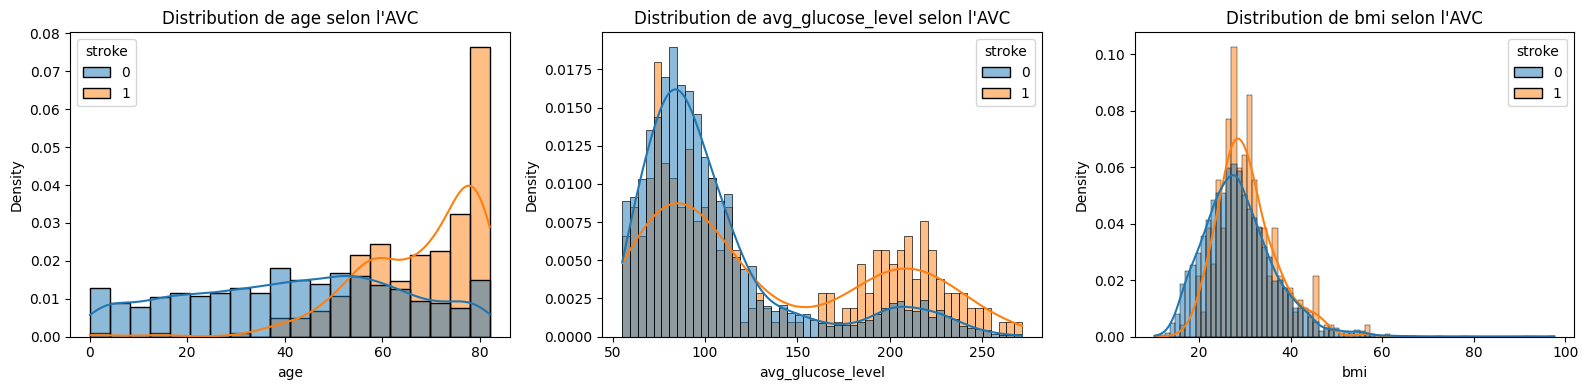

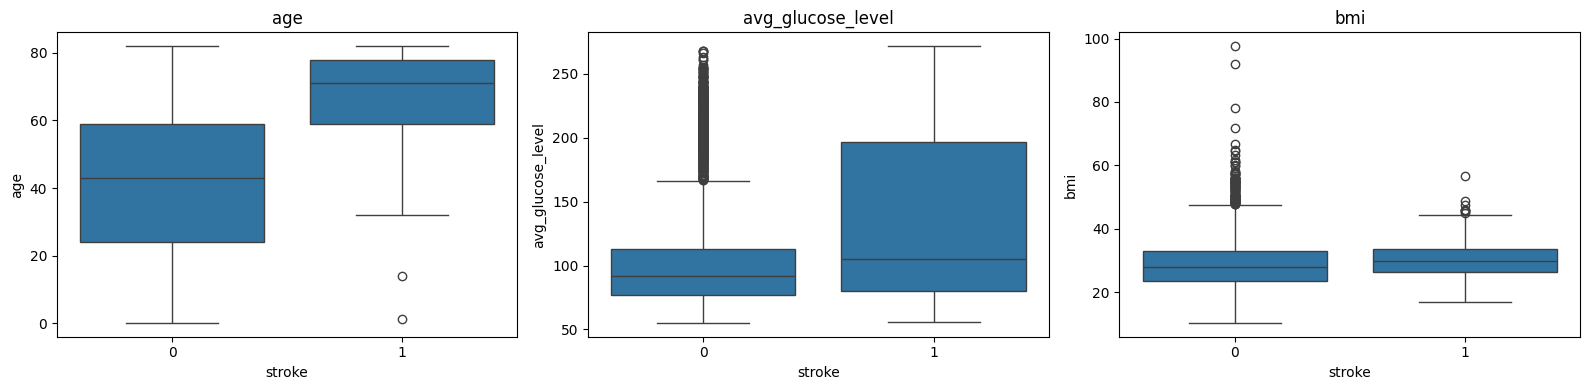

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="stroke", stat="density",
                 common_norm=False, kde=True, ax=ax)
    ax.set_title(f"Distribution de {col} selon l'AVC")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="stroke", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

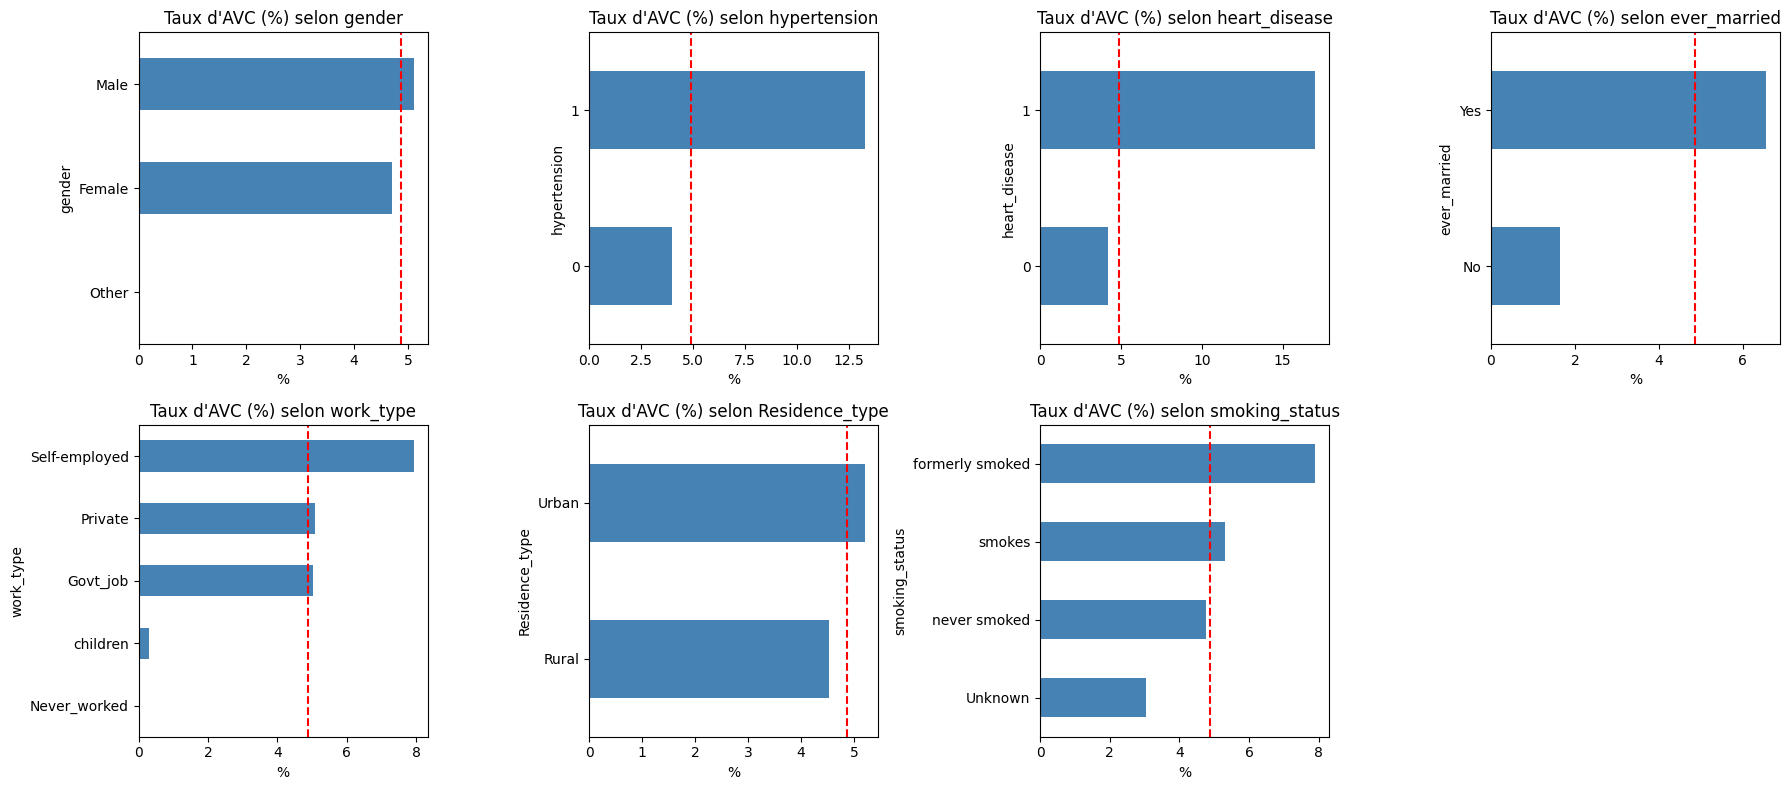

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for ax, col in zip(axes, cat_cols):
    taux = df.groupby(col)["stroke"].mean().sort_values() * 100
    taux.plot(kind="barh", ax=ax, color="steelblue")
    ax.axvline(df["stroke"].mean() * 100, color="red", linestyle="--")  # taux moyen
    ax.set_title(f"Taux d'AVC (%) selon {col}")
    ax.set_xlabel("%")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

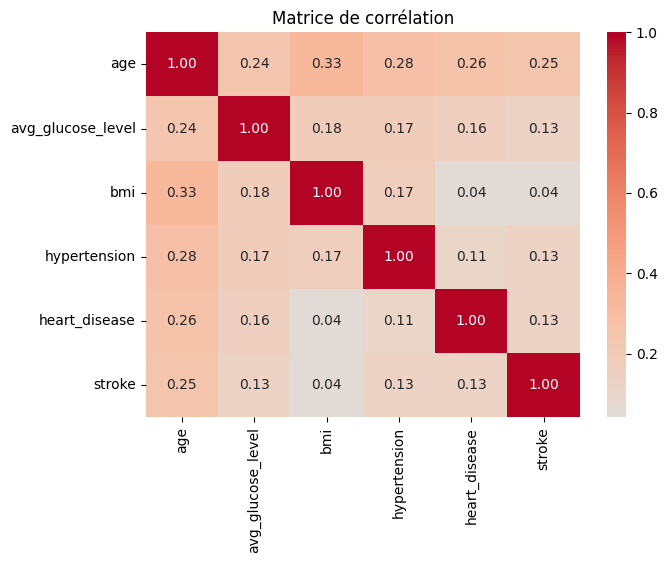

In [12]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + ["hypertension", "heart_disease", "stroke"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

## 2.4 Tests statistiques
- Variables catégorielles -> **test du Chi²** (indépendance avec `stroke`)
- Variables numériques -> **test de Mann-Whitney** (non paramétrique, car les distributions ne sont pas normales)

In [13]:
from scipy.stats import chi2_contingency, mannwhitneyu

resultats = []
for col in cat_cols:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df[col], df["stroke"]))
    resultats.append({"variable": col, "test": "Chi²", "p_value": p})
for col in num_cols:
    a = df.loc[df["stroke"] == 1, col].dropna()
    b = df.loc[df["stroke"] == 0, col].dropna()
    resultats.append({"variable": col, "test": "Mann-Whitney",
                      "p_value": mannwhitneyu(a, b).pvalue})

tests = pd.DataFrame(resultats).sort_values("p_value")
tests["significatif (p<0.05)"] = tests["p_value"] < 0.05
tests

,variable,test,p_value,significatif (p<0.05)
7,age,Mann-Whitney,3.726635e-71,True
2,heart_disease,Chi²,2.088785e-21,True
1,hypertension,Chi²,1.661622e-19,True
3,ever_married,Chi²,1.638902e-14,True
4,work_type,Chi²,5.397708e-10,True
8,avg_glucose_level,Mann-Whitney,3.640367e-09,True
6,smoking_status,Chi²,2.085400e-06,True
9,bmi,Mann-Whitney,1.026429e-04,True
5,Residence_type,Chi²,2.983317e-01,False
0,gender,Chi²,7.895491e-01,False


In [14]:
# ever_married est-il vraiment lié à l'AVC, ou est-ce l'effet de l'âge ?
pd.crosstab(pd.cut(df["age"], [0, 18, 40, 60, 100]), df["ever_married"],
            values=df["stroke"], aggfunc="mean").round(3)

ever_married,No,Yes
age,,
"(0, 18]",0.002,0.000
"(18, 40]",0.002,0.007
"(40, 60]",0.042,0.041
"(60, 100]",0.200,0.130


**Synthèse de l'analyse :**
- **Facteurs fortement liés à l'AVC :** âge (de loin le plus fort), maladie cardiaque, hypertension, glycémie.
- **Non significatifs :** sexe et lieu de résidence.
- **Facteur de confusion :** `ever_married` semble très significatif (6,6 % d'AVC chez les mariés contre 1,7 %), mais **à âge égal l'effet disparaît**. Les personnes mariées sont simplement plus âgées. Corrélation ≠ causalité : un modèle ML pourrait quand même utiliser cette variable, et il faudra vérifier si l'XAI le révèle.
- **Redondance :** `work_type = children` correspond exactement aux moins de 18 ans → information déjà contenue dans `age`.
- **Données manquantes informatives :** BMI absent (19,9 % d'AVC) et `smoking_status = Unknown` (30 % des lignes, dont 521 des 543 enfants de moins de 12 ans).
- **Valeurs extrêmes :** BMI jusqu'à 97,6 (13 patients > 60), physiologiquement très improbable.

## 2.5 Nettoyage

| Problème | Décision | Justification |
|---|---|---|
| `id` | Supprimé | Identifiant sans valeur médicale |
| `gender = Other` (1 ligne) | Ligne supprimée | Une seule observation, non apprenable |
| `bmi` manquant (201) | Indicatrice `bmi_missing` + imputation par la médiane du train | Manquants informatifs (MNAR) ; imputation après split pour éviter la fuite de données |
| `work_type` : `Never_worked` (22 patients, 0 AVC) | Fusion `children` + `Never_worked` → `Not_working` | Catégorie trop rare, majoritairement des mineurs |
| `smoking_status = Unknown` (30 %) | Conservé comme catégorie à part entière | Supprimer = perdre 30 % des données ; imputer = inventer un statut tabagique |
| BMI > 60 (13 patients) | Conservés, signalés | Suspects mais possibles ; modèles à arbres robustes |

In [15]:
df_clean = df.copy()

# 1. Supprimer l'identifiant
df_clean = df_clean.drop(columns="id")

# 2. Supprimer la seule ligne gender = "Other"
df_clean = df_clean[df_clean["gender"] != "Other"]

# 3. Indicatrice de BMI manquant (l'imputation se fera après le split)
df_clean["bmi_missing"] = df_clean["bmi"].isna().astype(int)

# 4. work_type : fusion des catégories sans activité
df_clean["work_type"] = df_clean["work_type"].replace(
    {"children": "Not_working", "Never_worked": "Not_working"})

print(df_clean.shape)
print(df_clean["work_type"].value_counts())
print(df_clean["smoking_status"].value_counts())


(5109, 12)
work_type
Private          2924
Self-employed     819
Not_working       709
Govt_job          657
Name: count, dtype: int64
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     884
smokes              789
Name: count, dtype: int64


## 2.6 Encodage des variables catégorielles
- **Binaires** (`gender`, `ever_married`, `Residence_type`) -> 0/1
- **Multi-classes** (`work_type`, `smoking_status`) -> **one-hot encoding** : une colonne 0/1 par catégorie.
  On évite un encodage 0,1,2,3 qui imposerait un ordre artificiel (ex. « smokes > never smoked »).
  Toutes les modalités sont conservées pour que les explications SHAP restent lisibles par catégorie.

In [16]:
df_enc = df_clean.copy()

# Variables binaires → 0/1
df_enc["gender"] = (df_enc["gender"] == "Male").astype(int)            # 1 = homme
df_enc["ever_married"] = (df_enc["ever_married"] == "Yes").astype(int)
df_enc["Residence_type"] = (df_enc["Residence_type"] == "Urban").astype(int)  # 1 = urbain

# Variables multi-classes → one-hot
df_enc = pd.get_dummies(df_enc, columns=["work_type", "smoking_status"], dtype=int)

print(df_enc.shape)
print(df_enc.columns.tolist())
print(df_enc.dtypes.value_counts())

(5109, 18)
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'avg_glucose_level', 'bmi', 'stroke', 'bmi_missing', 'work_type_Govt_job', 'work_type_Not_working', 'work_type_Private', 'work_type_Self-employed', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']
int64      15
float64     3
Name: count, dtype: int64


## 2.7 Découpage train / test
- 80 % entraînement / 20 % test, **stratifié** pour conserver 4,9 % d'AVC dans chaque partie.
- Le même découpage sera utilisé pour toutes les hypothèses (comparaisons équitables).
- La médiane du BMI est calculée **sur le train uniquement**, puis appliquée au test, pour éviter la fuite d'information.

In [17]:
from sklearn.model_selection import train_test_split

X = df_enc.drop(columns="stroke")
y = df_enc["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

# Imputation du BMI avec la médiane du TRAIN
mediane_bmi = X_train["bmi"].median()
X_train["bmi"] = X_train["bmi"].fillna(mediane_bmi)
X_test["bmi"] = X_test["bmi"].fillna(mediane_bmi)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("AVC train :", y_train.sum(), f"({y_train.mean():.3f})",
      "| AVC test :", y_test.sum(), f"({y_test.mean():.3f})")
print("Médiane BMI (train) :", mediane_bmi)
print("Manquants restants :", X_train.isna().sum().sum() + X_test.isna().sum().sum())

Train : (4087, 17) | Test : (1022, 17)
AVC train : 199 (0.049) | AVC test : 50 (0.049)
Médiane BMI (train) : 28.1
Manquants restants : 0


**Bilan de l'étape 2 :** données propres, entièrement numériques (17 variables), sans valeur manquante.
 Le jeu de test ne contient que **50 AVC** : chaque erreur sur un AVC fait varier le rappel de 2 points.
Les résultats devront donc être interprétés avec prudence (d'où l'intérêt de la validation croisée).

# 3. Hypothèses

Les hypothèses couvrent trois axes : **données** (qualité, déséquilibre, valeurs manquantes), **apprentissage automatique** (choix et coût des modèles) et **explicabilité** (globale, locale, modèles naturellement interprétables vs post-hoc).
Elles s'appuient sur l'analyse de l'étape 2 et sur la littérature. Certaines seront volontairement remises en question par les expériences.

**H1 :** L'accuracy n'est pas une métrique adaptée à ce jeu de données déséquilibré.

-> Prédiction : vraie, car avec 95 % de non-AVC, un modèle qui prédit toujours « non » obtient déjà 95 % d'accuracy.

**H2 :** Pondérer les classes améliore la détection des AVC.

->Prédiction : vraie, car le modèle sera forcé à prêter attention aux AVC, au prix de davantage de fausses alertes.

**H3 :** L'absence de valeur de BMI est une information utile pour prédire l'AVC.

->Prédiction : incertaine, car le lien est fort (19,9 % d'AVC) mais ne concerne que 201 patients.

**H4 :** Les modèles d'ensemble d'arbres sont plus performants que la régression logistique.

->Prédiction : plutôt fausse, car les relations sont simples ici (le risque augmente avec l'âge) et les AVC peu nombreux.


**H5 :** L'entraînement des modèles d'arbres est plus rapide que celui des réseaux de neurones.


->Prédiction : vraie, car un réseau de neurones nécessite de nombreuses itérations d'optimisation.

**H6 :** Un modèle utilisant peu de variables est aussi performant que le modèle complet.

->Prédiction : plutôt vraie, car seules quelques variables sont fortement liées à l'AVC.

**H7 :** L'âge est la variable la plus importante, quel que soit le modèle et la méthode d'explication.

->Prédiction : plutôt vraie, car l'âge est de loin la variable la plus significative (p ≈ 10⁻⁷¹).

**H8 :** Un modèle naturellement interprétable et un modèle boîte noire expliqué par SHAP s'appuient sur les mêmes variables.

->Prédiction : partiellement vraie, car les variables principales devraient concorder, mais pas l'ordre des variables secondaires.

**H9 :** SHAP et LIME donnent la même explication pour un même patient.

->Prédiction : partiellement fausse, car les deux méthodes reposent sur des principes différents.

**H10 :** Le modèle n'utilise pas la variable `ever_married`, qui n'est qu'un facteur de confusion de l'âge.

->Prédiction : incertaine, car un modèle apprend des corrélations, pas des causes.

**Références**
- Grinsztajn, L., Oyallon, E., Varoquaux, G. (2022). *Why do tree-based models still outperform deep learning on typical tabular data?* NeurIPS.
- Lundberg, S. M., Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions.* NeurIPS. (SHAP)
- Ribeiro, M. T., Singh, S., Guestrin, C. (2016). *"Why Should I Trust You?" Explaining the Predictions of Any Classifier.* KDD. (LIME)
- Rudin, C. (2019). *Stop explaining black box machine learning models for high stakes decisions and use interpretable models instead.* Nature Machine Intelligence.
- Strobl, C., Boulesteix, A.-L., Zeileis, A., Hothorn, T. (2007). Bias in random forest variable importance measures. BMC Bioinformatics.
- Slack, D., Hilgard, S., Jia, E., Singh, S., Lakkaraju, H. (2020). Fooling LIME and SHAP: Adversarial Attacks on Post hoc Explanation Methods. AIES.

# 4. Protocole expérimental

## 4.0 Cadre commun à toutes les expériences
- **Données :** découpage train/test de l'étape 2.7 (80/20 stratifié), identique pour toutes les hypothèses.
- **Reproductibilité :** graine aléatoire fixée (`SEED = 42`).
- **Validation croisée :** 5 plis stratifiés sur le train, pour obtenir une moyenne ± écart-type (le test ne contient que 50 AVC).

**Modèles utilisés**

| Modèle | Type | Configuration |
|---|---|---|
| Régression logistique (LR) | Naturellement interprétable | Variables standardisées, `class_weight="balanced"` |
| Arbre de décision (DT) | Naturellement interprétable | Profondeur max = 5 |
| Random Forest (RF) | Ensemble d'arbres (boîte noire) | 300 arbres, `class_weight="balanced"` |
| XGBoost (XGB) | Ensemble d'arbres (boîte noire) | 300 arbres, profondeur 3, `scale_pos_weight` |
| Réseau de neurones (MLP) | Boîte noire | 2 couches cachées (64, 32) |

**Métriques**

| Métrique | Ce qu'elle mesure |
|---|---|
| Accuracy | % de bonnes prédictions (trompeuse si déséquilibre) |
| Balanced accuracy | Moyenne du rappel de chaque classe (50 % = hasard) |
| Rappel (recall) | % des AVC réellement détectés |
| Précision | % des alertes « AVC » qui sont vraies |
| AUC-ROC | Capacité à classer un malade au-dessus d'un non-malade, indépendamment du seuil |
| Corrélation de Spearman | Concordance entre deux classements de variables (de −1 à 1) |

## 4.1 Protocoles : données et apprentissage



**H1 : L'accuracy n'est pas une métrique adaptée.**
1. Entraîner un classifieur naïf (`DummyClassifier`, prédit toujours la classe majoritaire) et une LR **sans** pondération des classes.
2. Évaluer sur le test : accuracy, balanced accuracy, rappel.
3. *Validée si* le classifieur naïf obtient une accuracy > 90 % avec une balanced accuracy de 50 % et un rappel nul.

**H2 : Pondérer les classes améliore la détection des AVC.**
1. Entraîner une LR et une RF, chacune **avec** et **sans** `class_weight="balanced"`.
2. Évaluer sur le test : rappel, précision, balanced accuracy.
3. *Validée si* la pondération augmente le rappel et la balanced accuracy pour les deux modèles (on observera aussi l'effet sur la précision).

**H3 : L'absence de BMI est une information utile.**
1. Entraîner une LR et un XGB **avec** et **sans** la variable `bmi_missing`.
2. Mesurer l'AUC-ROC en validation croisée (5 plis).
3. *Validée si* l'AUC moyenne augmente avec `bmi_missing` **et** si le gain est positif sur au moins 4 plis sur 5.

**H4 : Les ensembles d'arbres sont plus performants que la régression logistique.**
1. Entraîner LR, RF et XGB sur les mêmes données.
2. Mesurer l'AUC-ROC en validation croisée (moyenne ± écart-type), puis AUC-ROC et balanced accuracy sur le test.
3. *Validée si* RF et XGB obtiennent une AUC moyenne supérieure à celle de la LR.

**H5 : Les arbres s'entraînent plus vite que les réseaux de neurones.**
1. Rééquilibrer le train par sur-échantillonnage des AVC (le MLP ne gère pas `class_weight`), puis entraîner un DT et un MLP sur ces mêmes données.
2. Mesurer le temps d'entraînement moyen sur 5 répétitions et la balanced accuracy sur le test.
3. *Validée si* le DT est au moins 10 fois plus rapide **et** obtient une balanced accuracy au moins égale à celle du MLP

**H6 : Un modèle avec peu de variables est aussi performant que le modèle complet.**
1. Sélectionner les 4 variables les plus importantes selon la RF entraînée en H4.
2. Réentraîner la LR et le XGB sur ces 4 variables uniquement.
3. Comparer l'AUC-ROC (validation croisée et test) au modèle complet.
4. *Validée si* le modèle réduit conserve au moins 95 % de l'AUC du modèle complet.

## 4.2 Protocoles : explicabilité

**H7 : L'âge est la variable la plus importante quelle que soit la méthode.**
1. Calculer l'importance des variables avec 4 méthodes :
   - coefficients (en valeur absolue) de la LR → *interprétable par nature, globale* ;
   - importance par impureté de la RF → *spécifique aux arbres, globale* ;
   - importance par permutation sur le XGB → *post-hoc, agnostique, globale* ;
   - moyenne des |valeurs SHAP| du XGB → *post-hoc, globale (agrégation d'explications locales)*.
2. Relever le rang de `age` dans chaque classement.
3. *Validée si* `age` est classée 1ʳᵉ par les 4 méthodes.

**H8 : Modèle interprétable et boîte noire + SHAP s'appuient sur les mêmes variables.**
1. Classer les 17 variables selon les |coefficients| de la LR et selon la moyenne des |SHAP| du XGB.
2. Calculer la corrélation de Spearman entre les deux classements et le nombre de variables communes dans les top 5.
3. *Validée si* la corrélation de Spearman est > 0,7.


**H9 : SHAP et LIME donnent la même explication pour un même patient.**
1. Sélectionner les 5 premiers patients du test ayant eu un AVC.
2. Pour chacun, expliquer la prédiction du XGB avec SHAP et avec LIME, et relever les 3 variables les plus influentes.
3. Compter le nombre de variables communes aux deux top 3 (de 0 à 3).
4. *Validée si* les top 3 sont identiques (3/3) pour au moins 4 patients sur 5.

**H10 : Le modèle n'utilise pas `ever_married`.**
1. Relever le rang et la part d'importance de `ever_married` (SHAP pour le XGB, coefficients pour la LR).
2. Réentraîner la LR et le XGB **sans** `ever_married` et comparer l'AUC-ROC en validation croisée.
3. *Validée si* `ever_married` n'est dans le top 5 d'aucun modèle **et** si sa suppression fait varier l'AUC de moins de 0,005.

# 5. Mise en œuvre des protocoles

## 5.0 Préparation commune
Import des modèles et métriques, définition d'une fonction d'évaluation et des modèles réutilisés dans plusieurs expériences.

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, recall_score,
                             precision_score, roc_auc_score, confusion_matrix)
from xgboost import XGBClassifier

# Validation croisée : 5 plis stratifiés
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Ratio utilisé par XGBoost pour compenser le déséquilibre
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("Ratio non-AVC / AVC :", round(ratio, 2))

def evaluer(modele, X_t=X_test, y_t=y_test):
    """Calcule les 5 métriques du protocole sur le jeu de test."""
    pred = modele.predict(X_t)
    proba = modele.predict_proba(X_t)[:, 1]
    return {"accuracy": accuracy_score(y_t, pred),
            "balanced_acc": balanced_accuracy_score(y_t, pred),
            "rappel": recall_score(y_t, pred),
            "precision": precision_score(y_t, pred, zero_division=0),
            "auc_roc": roc_auc_score(y_t, proba)}

def creer_modeles():
    """Crée les 3 modèles principaux, avec la même configuration partout."""
    return {
        "LR": make_pipeline(StandardScaler(),
                            LogisticRegression(max_iter=1000, class_weight="balanced")),
        "RF": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                     class_weight="balanced", random_state=SEED, n_jobs=-1),
        "XGB": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                             scale_pos_weight=ratio, random_state=SEED, eval_metric="logloss"),
    }

Ratio non-AVC / AVC : 19.54


## 5.1 H1 : L'accuracy n'est pas une métrique adaptée

In [19]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
lr_sans_poids = make_pipeline(StandardScaler(),
                              LogisticRegression(max_iter=1000)).fit(X_train, y_train)

res_h1 = pd.DataFrame({"Naïf (toujours 0)": evaluer(dummy),
                       "LR sans pondération": evaluer(lr_sans_poids)}).T.round(3)
res_h1

,accuracy,balanced_acc,rappel,precision,auc_roc
Naïf (toujours 0),0.951,0.500,0.00,0.0,0.500
LR sans pondération,0.951,0.509,0.02,0.5,0.837


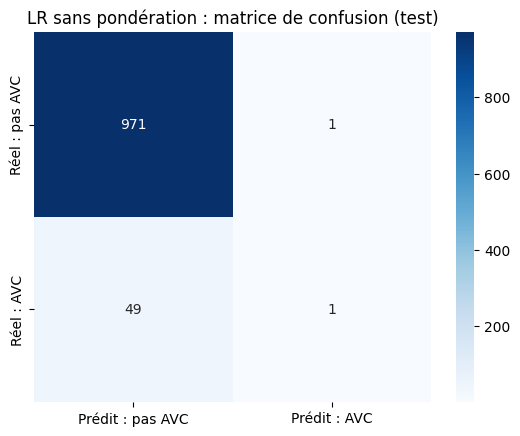

In [20]:
cm = confusion_matrix(y_test, lr_sans_poids.predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Prédit : pas AVC", "Prédit : AVC"],
            yticklabels=["Réel : pas AVC", "Réel : AVC"])
plt.title("LR sans pondération : matrice de confusion (test)")
plt.show()

**Résultat H1 :  validée.**
Le classifieur naïf atteint 95,1 % d'accuracy sans détecter un seul AVC (balanced accuracy = 50 %, rappel = 0).
La LR non pondérée obtient la même accuracy mais ne détecte qu'**1 AVC sur 50**. En pratique, elle se comporte presque comme le modèle naïf.
-> L'accuracy masque complètement l'échec du modèle sur la classe qui nous intéresse. On utilisera la balanced accuracy, le rappel et l'AUC-ROC.

*Remarque :* l'AUC de la LR (0,837) est bonne. Le modèle **sait classer** les patients par niveau de risque, mais le seuil par défaut de 0,5 est inadapté quand seulement 5 % des patients sont positifs.

## 5.2 H2 : Pondérer les classes améliore la détection des AVC

In [21]:
res_h2 = {}
for nom, poids in [("sans pondération", None), ("avec pondération", "balanced")]:
    lr = make_pipeline(StandardScaler(),
                       LogisticRegression(max_iter=1000, class_weight=poids)).fit(X_train, y_train)
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=poids,
                                random_state=SEED, n_jobs=-1).fit(X_train, y_train)
    res_h2[f"LR {nom}"] = evaluer(lr)
    res_h2[f"RF {nom}"] = evaluer(rf)

res_h2 = pd.DataFrame(res_h2).T[["rappel", "precision", "balanced_acc", "accuracy"]].round(3)
res_h2

,rappel,precision,balanced_acc,accuracy
LR sans pondération,0.02,0.500,0.509,0.951
RF sans pondération,0.00,0.000,0.500,0.951
LR avec pondération,0.80,0.143,0.777,0.755
RF avec pondération,0.22,0.186,0.585,0.915


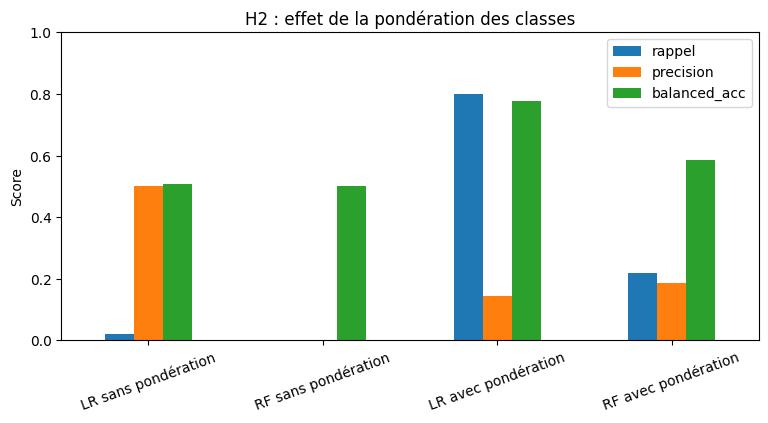

In [22]:
res_h2[["rappel", "precision", "balanced_acc"]].plot(kind="bar", figsize=(9, 4))
plt.title("H2 : effet de la pondération des classes")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

**Résultat H2 : validée.**
La pondération fait passer le rappel de la LR de **2 % à 80 %** (40 AVC détectés sur 50) et celui de la RF de **0 % à 22 %**. La balanced accuracy passe d'environ 0,50 à 0,78 (LR) et 0,59 (RF).
L'effet est donc net pour la LR, mais **beaucoup plus faible pour la RF** : avec `min_samples_leaf=5`, ses feuilles restent dominées par les non-AVC malgré la pondération.
**Contrepartie :** la précision chute à environ 14-19 %. Sur 100 alertes « AVC », seules 14 à 19 sont justifiées.
-> En dépistage médical, ce compromis est généralement acceptable : **rater un AVC coûte bien plus cher qu'une fausse alerte**, qui entraîne seulement un examen complémentaire.

## 5.3 H3 : L'absence de BMI est une information utile

In [23]:
res_h3 = []
for nom in ["LR", "XGB"]:
    modele = creer_modeles()[nom]
    avec = cross_val_score(clone(modele), X_train, y_train,
                           cv=cv, scoring="roc_auc")
    sans = cross_val_score(clone(modele), X_train.drop(columns="bmi_missing"), y_train,
                           cv=cv, scoring="roc_auc")
    gain = avec - sans
    res_h3.append({"modèle": nom,
                   "AUC sans bmi_missing": sans.mean(),
                   "AUC avec bmi_missing": avec.mean(),
                   "gain moyen": gain.mean(),
                   "plis avec gain > 0": f"{(gain > 0).sum()}/5"})

res_h3 = pd.DataFrame(res_h3).set_index("modèle").round(4)
res_h3

,AUC sans bmi_missing,AUC avec bmi_missing,gain moyen,plis avec gain > 0
modèle,,,,
LR,0.8388,0.8536,0.0148,5/5
XGB,0.8214,0.8236,0.0022,3/5


**Résultat H3 :  partiellement validée.**
- **LR :** l'indicatrice `bmi_missing` augmente l'AUC de 0,839 à 0,854 (+0,015), et ce sur **les 5 plis** -> validée.
- **XGB :** gain quasi nul (+0,002) et positif sur seulement 3 plis sur 5 ->non validée.

-> L'information est réelle (confirmée par l'analyse statistique de l'étape 2), mais **son utilité dépend du modèle**. La LR, modèle linéaire, ne peut exploiter cette information que si on la lui fournit explicitement sous forme de variable. Le gain pour XGB reste dans la marge de variation entre plis.
-> Leçon pour la préparation des données : une valeur manquante n'est pas toujours un « trou » à combler, elle peut être un **signal médical** (par exemple, un patient admis en urgence dont on n'a pas mesuré le poids).

## 5.4 H4 : Les ensembles d'arbres sont plus performants que la régression logistique

In [24]:
res_cv, res_test = {}, {}
for nom, modele in creer_modeles().items():
    res_cv[nom] = cross_val_score(clone(modele), X_train, y_train,
                                  cv=cv, scoring="roc_auc")
    res_test[nom] = evaluer(modele.fit(X_train, y_train))

res_h4 = pd.DataFrame({
    "AUC CV (moyenne)":    {n: s.mean() for n, s in res_cv.items()},
    "AUC CV (écart-type)": {n: s.std() for n, s in res_cv.items()},
    "AUC test":            {n: r["auc_roc"] for n, r in res_test.items()},
    "balanced_acc test":   {n: r["balanced_acc"] for n, r in res_test.items()},
}).round(3)
res_h4

,AUC CV (moyenne),AUC CV (écart-type),AUC test,balanced_acc test
LR,0.854,0.024,0.837,0.777
RF,0.846,0.027,0.820,0.585
XGB,0.824,0.038,0.815,0.756


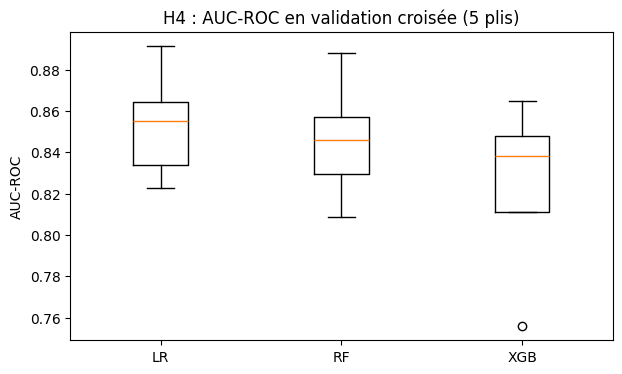

In [25]:
plt.figure(figsize=(7, 4))
plt.boxplot(list(res_cv.values()))
plt.xticks(range(1, len(res_cv) + 1), list(res_cv.keys()))
plt.title("H4 : AUC-ROC en validation croisée (5 plis)")
plt.ylabel("AUC-ROC")
plt.show()

**Résultat H4 :  infirmée.**
La régression logistique obtient la **meilleure AUC** (0,854 en CV, 0,837 en test), devant la Random Forest (0,846) et XGBoost (0,824). Elle a aussi la meilleure balanced accuracy en test (0,777).
Les écarts restent toutefois **inférieurs ou proches de l'écart-type** entre plis (≈ 0,02-0,04) : les trois modèles ont des performances comparables.

**Pourquoi ce résultat contredit la littérature (Grinsztajn et al., 2022) :**
- les relations sont **simples et presque monotones** (le risque augmente avec l'âge, la glycémie…), ce qu'un modèle linéaire capture bien ;
- seulement **199 AVC** dans le train : trop peu pour que des modèles complexes apprennent des interactions fiables sans surapprendre ;
- les hyperparamètres n'ont pas été optimisés, ce qui pénalise surtout XGBoost.

-> **Conséquence pour l'explicabilité :** un modèle naturellement interprétable suffit ici. Il n'y a pas de compromis performance/interprétabilité à faire, ce qui rejoint l'argument de Rudin (2019).

## 5.5 H5 : Les arbres s'entraînent plus vite que les réseaux de neurones
Le MLP de scikit-learn ne gère pas `class_weight` : pour une comparaison équitable, les deux modèles sont entraînés sur le même train **rééquilibré par sur-échantillonnage** des AVC.

In [26]:
from sklearn.utils import resample

X_avc = X_train[y_train == 1]
X_non = X_train[y_train == 0]

# On duplique aléatoirement les AVC jusqu'à avoir autant d'AVC que de non-AVC
X_avc_sur = resample(X_avc, n_samples=len(X_non), replace=True, random_state=SEED)

X_equil = pd.concat([X_non, X_avc_sur])
y_equil = pd.Series([0] * len(X_non) + [1] * len(X_avc_sur))
print(X_equil.shape, y_equil.value_counts().to_dict())

(7776, 17) {0: 3888, 1: 3888}


In [27]:
modeles_h5 = {
    "Arbre de décision": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Réseau de neurones (MLP)": make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500,
                      early_stopping=True, random_state=SEED)),
}

res_h5 = {}
for nom, modele in modeles_h5.items():
    temps = []
    for _ in range(5):                       # 5 répétitions pour un temps fiable
        debut = time.perf_counter()
        modele.fit(X_equil, y_equil)
        temps.append(time.perf_counter() - debut)
    r = evaluer(modele)
    res_h5[nom] = {"temps moyen (s)": np.mean(temps), "balanced_acc": r["balanced_acc"],
                   "rappel": r["rappel"], "auc_roc": r["auc_roc"]}

res_h5 = pd.DataFrame(res_h5).T.round(4)
print("Le MLP est",
      round(res_h5.loc["Réseau de neurones (MLP)", "temps moyen (s)"]
            / res_h5.loc["Arbre de décision", "temps moyen (s)"]),
      "fois plus lent que l'arbre")
res_h5

Le MLP est 340 fois plus lent que l'arbre


,temps moyen (s),balanced_acc,rappel,auc_roc
Arbre de décision,0.0154,0.7540,0.72,0.7802
Réseau de neurones (MLP),5.2356,0.6219,0.32,0.7495


**Résultat H5 :  validée.**
L'arbre de décision s'entraîne **plus de 300 fois plus vite** que le MLP (quelques millisecondes contre plus d'une seconde) **et** obtient une meilleure balanced accuracy (0,75 contre 0,62).
Comme dans l'exemple du protocole, si l'on ne retient que les modèles avec une balanced accuracy > 0,70, **seul l'arbre de décision est retenu**.

**Remarques critiques :**
- le MLP détecte peu d'AVC (rappel 0,32) : le sur-échantillonnage par **duplication** lui fait mémoriser les mêmes patients ;
- le MLP n'a pas été optimisé (architecture, taux d'apprentissage) : il pourrait faire mieux, mais au prix d'un temps de réglage encore plus important ;
- le temps mesuré dépend de la machine : seul le **rapport** entre les deux modèles est interprétable.

## 5.6 Entraînement des modèles de référence
Les trois modèles principaux sont entraînés une fois sur tout le train. Ils servent pour H6 à H10.

In [28]:
modeles = creer_modeles()
for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    print(nom, "entraîné")

LR entraîné
RF entraîné
XGB entraîné


## 5.7 H6 : Un modèle avec peu de variables est aussi performant que le modèle complet

In [29]:
imp_rf = pd.Series(modeles["RF"].feature_importances_,
                   index=X_train.columns).sort_values(ascending=False)
top4 = imp_rf.index[:4].tolist()
print("4 variables retenues :", top4)
imp_rf.head(6).round(3)

4 variables retenues : ['age', 'avg_glucose_level', 'bmi', 'bmi_missing']


,0
age,0.429
avg_glucose_level,0.162
bmi,0.133
bmi_missing,0.039
hypertension,0.037
ever_married,0.034


In [30]:
res_h6 = []
for nom in ["LR", "XGB"]:
    m = creer_modeles()[nom]
    cv_complet = cross_val_score(clone(m), X_train, y_train, cv=cv, scoring="roc_auc").mean()
    cv_reduit = cross_val_score(clone(m), X_train[top4], y_train, cv=cv, scoring="roc_auc").mean()
    test_complet = evaluer(modeles[nom])["auc_roc"]
    test_reduit = evaluer(clone(m).fit(X_train[top4], y_train), X_t=X_test[top4])["auc_roc"]
    res_h6.append({"modèle": nom,
                   "AUC CV complet (17 var.)": cv_complet,
                   "AUC CV réduit (4 var.)": cv_reduit,
                   "% conservé (CV)": 100 * cv_reduit / cv_complet,
                   "AUC test complet": test_complet,
                   "AUC test réduit": test_reduit,
                   "% conservé (test)": 100 * test_reduit / test_complet})

res_h6 = pd.DataFrame(res_h6).set_index("modèle").round(3)
res_h6

,AUC CV complet (17 var.),AUC CV réduit (4 var.),% conservé (CV),AUC test complet,AUC test réduit,% conservé (test)
modèle,,,,,,
LR,0.854,0.853,99.917,0.837,0.837,99.941
XGB,0.824,0.821,99.725,0.815,0.803,98.503


**Résultat H6 :  validée.**
Avec seulement **4 variables sur 17** (âge, glycémie, BMI, BMI manquant), la LR conserve **99,9 %** de son AUC et XGBoost entre **98,5 % et 99,7 %**, bien au-dessus du seuil de 95 %.
-> Les 13 autres variables n'apportent presque rien.
-> **Intérêt pour l'explicabilité :** un modèle à 4 variables est beaucoup plus simple à expliquer à un médecin et demande moins de données à collecter.

 *Limite :* l'hypertension et la maladie cardiaque, facteurs de risque reconnus de l'AVC, ne sont pas retenues. L'importance par impureté de la RF **favorise les variables continues** (âge, glycémie, BMI) par rapport aux variables binaires (Strobl et al., 2007). Une sélection fondée sur l'avis médical aurait pu donner un autre résultat.

## 5.8 H7 : L'âge est la variable la plus importante quelle que soit la méthode
Quatre méthodes d'explicabilité globale sont comparées :

| Méthode | Modèle | Famille |
|---|---|---|
| \|Coefficients\| | LR | Interprétable par nature |
| Importance par impureté | RF | Spécifique aux arbres |
| Importance par permutation | XGB | Post-hoc, agnostique au modèle |
| Moyenne des \|valeurs SHAP\| | XGB | Post-hoc, agrégation d'explications locales |

In [31]:
from sklearn.inspection import permutation_importance
import shap

# 1. Coefficients de la LR (variables standardisées → comparables entre elles)
coef_lr = pd.Series(np.abs(modeles["LR"][-1].coef_[0]), index=X_train.columns)

# 2. Importance par impureté de la RF (déjà calculée en H6) → imp_rf

# 3. Importance par permutation du XGB (baisse d'AUC quand on mélange une variable)
perm = permutation_importance(modeles["XGB"], X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=SEED)
imp_perm = pd.Series(perm.importances_mean, index=X_train.columns)

# 4. SHAP sur le XGB
explainer = shap.TreeExplainer(modeles["XGB"])
shap_values = explainer.shap_values(X_test)
imp_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=X_train.columns)

importances = pd.DataFrame({"LR |coefficients|": coef_lr, "RF impureté": imp_rf,
                            "XGB permutation": imp_perm, "XGB SHAP": imp_shap})
rangs = importances.rank(ascending=False, method="min").astype(int)
print("Rang de 'age' selon chaque méthode :")
print(rangs.loc["age"])
rangs.sort_values("XGB SHAP").head(6)

Rang de 'age' selon chaque méthode :
LR |coefficients|    1
RF impureté          1
XGB permutation      1
XGB SHAP             1
Name: age, dtype: int64


,LR |coefficients|,RF impureté,XGB permutation,XGB SHAP
age,1,1,1,1
bmi,8,3,2,2
avg_glucose_level,5,2,3,3
bmi_missing,2,4,10,4
ever_married,13,6,7,5
hypertension,4,5,12,6


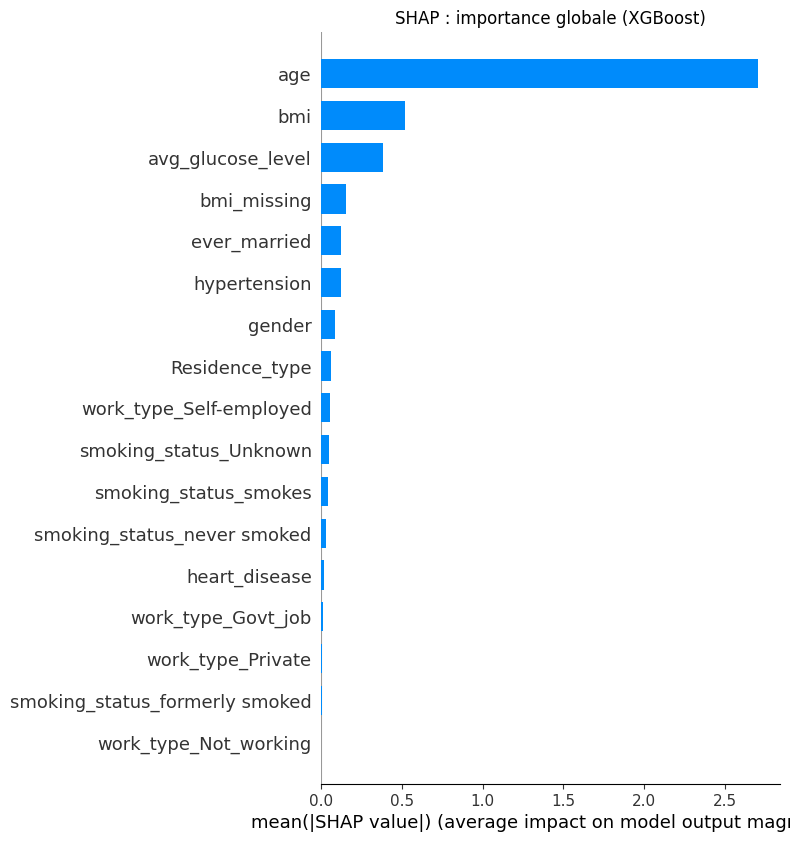

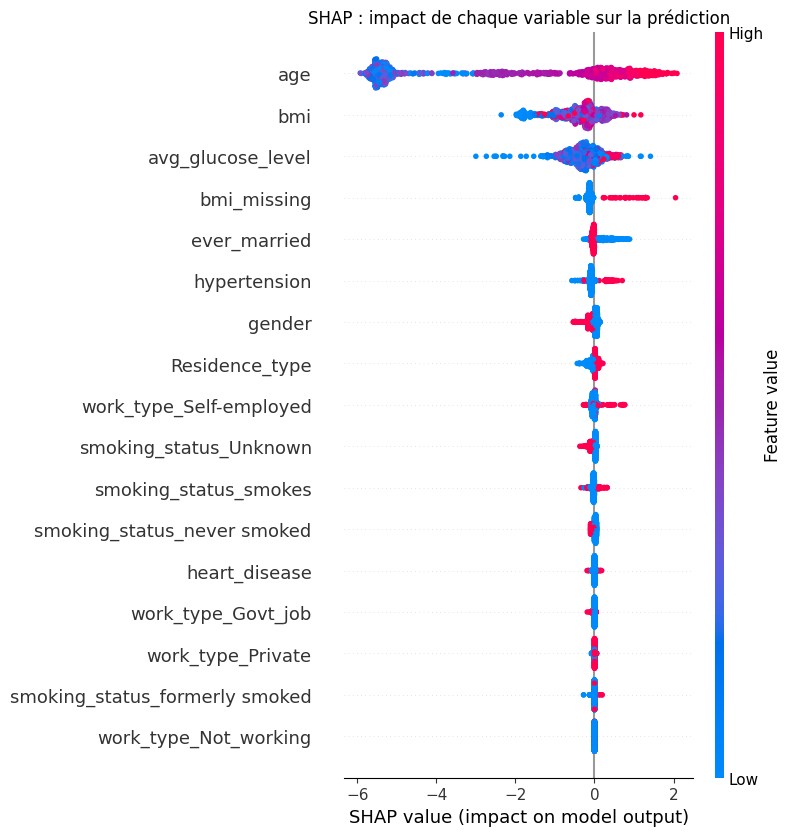

In [32]:
# Importance globale : moyenne des |SHAP|
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("SHAP : importance globale (XGBoost)")
plt.show()

# Beeswarm : chaque point est un patient ; la couleur indique la valeur de la variable
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP : impact de chaque variable sur la prédiction")
plt.show()

**Résultat H7 :  validée.**
L'âge est classé **1er par les 4 méthodes**, avec une très large avance (sa valeur SHAP moyenne est environ 5 fois plus élevée que celle de la 2ᵉ variable).
Le beeswarm SHAP confirme le **sens médical** de la relation : plus l'âge est élevé, plus le risque prédit augmente.

**Mais au-delà de la 1ʳᵉ place, les méthodes divergent fortement :**
- le BMI est 2ᵉ selon SHAP et la permutation, mais seulement 8ᵉ selon la LR ;
- l'hypertension est 4ᵉ selon la LR, mais 12ᵉ selon la permutation.
-> Le classement des variables **dépend du modèle ET de la méthode d'explication**. Il ne faut pas présenter un seul classement comme « la vérité ».

## 5.9 H8 : Modèle interprétable et boîte noire + SHAP s'appuient sur les mêmes variables

In [33]:
from scipy.stats import spearmanr

rho, p_value = spearmanr(coef_lr, imp_shap)
top5_lr = set(coef_lr.nlargest(5).index)
top5_shap = set(imp_shap.nlargest(5).index)

print(f"Corrélation de Spearman : {rho:.3f} (p = {p_value:.3f})")
print("Variables communes aux deux top 5 :", top5_lr & top5_shap)
print("Seulement dans le top 5 LR   :", top5_lr - top5_shap)
print("Seulement dans le top 5 SHAP :", top5_shap - top5_lr)

Corrélation de Spearman : 0.493 (p = 0.045)
Variables communes aux deux top 5 : {'avg_glucose_level', 'bmi_missing', 'age'}
Seulement dans le top 5 LR   : {'work_type_Not_working', 'hypertension'}
Seulement dans le top 5 SHAP : {'bmi', 'ever_married'}


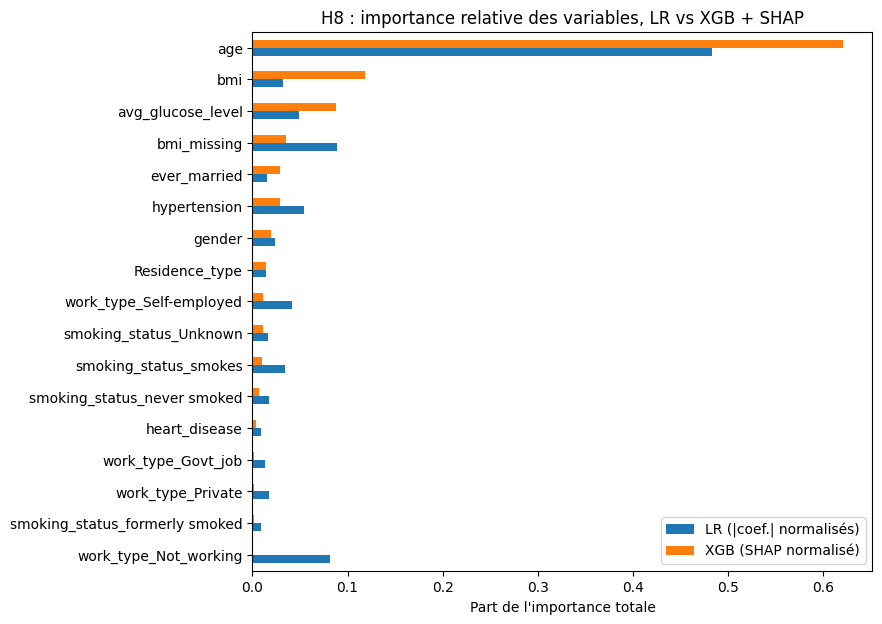

In [34]:
comparaison = pd.DataFrame({
    "LR (|coef.| normalisés)": coef_lr / coef_lr.sum(),
    "XGB (SHAP normalisé)": imp_shap / imp_shap.sum()
}).sort_values("XGB (SHAP normalisé)")

comparaison.plot(kind="barh", figsize=(8, 7))
plt.title("H8 : importance relative des variables, LR vs XGB + SHAP")
plt.xlabel("Part de l'importance totale")
plt.show()

**Résultat H8 :  infirmée** (ρ = 0,49 < 0,7).
Les deux approches s'accordent sur l'essentiel : **3 variables communes sur 5** (âge, glycémie, BMI manquant), avec l'âge 1er dans les deux cas. En revanche, elles divergent sur le reste :
- **BMI :** 2ᵉ pour XGB, 8ᵉ pour la LR. L'effet du BMI est probablement **non linéaire** (risque accru dans certaines plages seulement), ce que les arbres captent et pas un modèle linéaire.
- **`work_type_Not_working`** (les enfants) : 3ᵉ pour la LR, dernière pour XGB. La LR a besoin de cette variable pour corriger son effet linéaire de l'âge chez les enfants (risque quasi nul), alors que les arbres découpent directement l'âge par seuils.
- **`ever_married`** apparaît dans le top 5 de XGB (voir H10).

-> Deux modèles de performance comparable (H4) peuvent **raisonner différemment**. L'explication décrit **le modèle**, pas la réalité médicale.
 *Limite méthodologique :* les coefficients d'une LR et les valeurs SHAP ne mesurent pas exactement la même chose (effet d'une variation d'un écart-type vs contribution moyenne à la prédiction). La comparaison porte donc sur les **classements**, pas sur les valeurs.

## 5.10 H9 : SHAP et LIME donnent la même explication pour un même patient
Explications **locales** : pourquoi le modèle XGBoost a-t-il donné *cette* probabilité à *ce* patient ?
- **SHAP** répartit la prédiction entre les variables selon la théorie des jeux (valeurs de Shapley).
- **LIME** perturbe le patient, observe les nouvelles prédictions et ajuste autour de lui un modèle linéaire simple.

In [35]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["Pas d'AVC", "AVC"],
    mode="classification",
    random_state=SEED)

def predict_xgb(donnees):
    """LIME envoie des tableaux numpy : on les remet en DataFrame pour XGBoost."""
    return modeles["XGB"].predict_proba(pd.DataFrame(donnees, columns=X_test.columns))

# Les 5 premiers patients du test ayant réellement eu un AVC
patients = np.where(y_test.values == 1)[0][:5]
print("Patients sélectionnés :", patients)

Patients sélectionnés : [ 33  61  65 135 153]


In [36]:
res_h9 = []
for i in patients:
    top3_shap = pd.Series(np.abs(shap_values[i]),
                          index=X_test.columns).nlargest(3).index.tolist()
    exp = lime_explainer.explain_instance(X_test.values[i], predict_xgb, num_features=3)
    top3_lime = [X_test.columns[j] for j, _ in exp.as_map()[1]]
    res_h9.append({"patient": i,
                   "proba AVC": predict_xgb(X_test.values[i:i+1])[0, 1],
                   "top 3 SHAP": top3_shap,
                   "top 3 LIME": top3_lime,
                   "communes": len(set(top3_shap) & set(top3_lime))})

res_h9 = pd.DataFrame(res_h9).round(3)
print("Patients avec top 3 identique :", (res_h9["communes"] == 3).sum(), "/ 5")
print("Nombre moyen de variables communes :", res_h9["communes"].mean(), "/ 3")
res_h9

Patients avec top 3 identique : 0 / 5
Nombre moyen de variables communes : 1.6 / 3


,patient,proba AVC,top 3 SHAP,top 3 LIME,communes
0,33,0.549,"[age, bmi, smoking_status_Unknown]","[age, bmi_missing, avg_glucose_level]",1
1,61,0.890,"[age, hypertension, bmi]","[age, bmi_missing, hypertension]",2
2,65,0.527,"[age, avg_glucose_level, bmi]","[age, bmi_missing, avg_glucose_level]",2
3,135,0.061,"[age, bmi_missing, avg_glucose_level]","[age, bmi_missing, hypertension]",2
4,153,0.773,"[bmi, age, avg_glucose_level]","[age, bmi_missing, hypertension]",1


Patient 33 : {'age': 76.0, 'hypertension': 0.0, 'heart_disease': 0.0, 'avg_glucose_level': 207.28, 'bmi': 34.9}


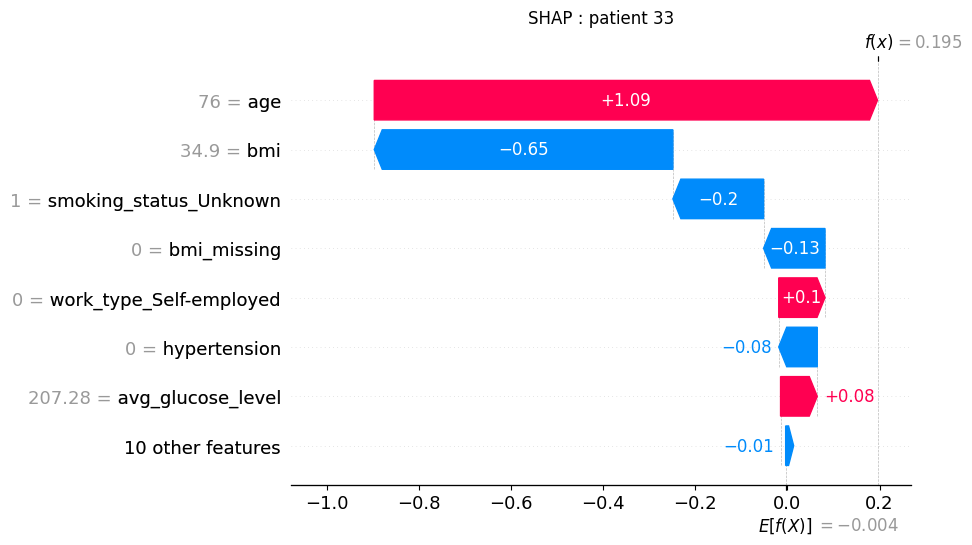

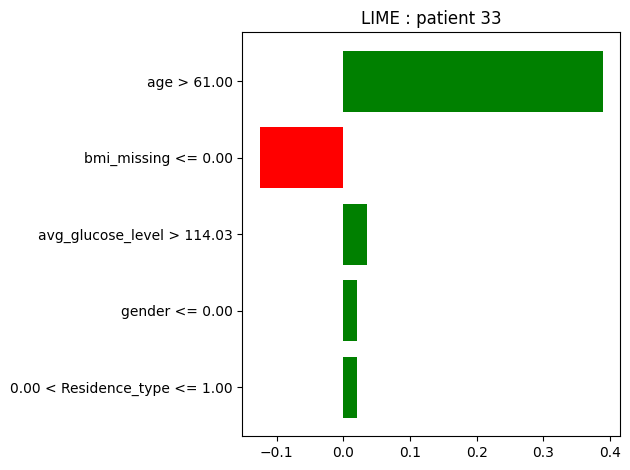

In [37]:
i = patients[0]
print("Patient", i, ":", X_test.iloc[i][["age", "hypertension", "heart_disease",
                                         "avg_glucose_level", "bmi"]].to_dict())

# Explication SHAP (waterfall)
explication = shap.Explanation(values=shap_values[i],
                               base_values=float(np.ravel(explainer.expected_value)[0]),
                               data=X_test.iloc[i].values,
                               feature_names=X_test.columns.tolist())
shap.plots.waterfall(explication, max_display=8, show=False)
plt.title(f"SHAP : patient {i}")
plt.show()

# Explication LIME
exp = lime_explainer.explain_instance(X_test.values[i], predict_xgb, num_features=5)
exp.as_pyplot_figure()
plt.title(f"LIME : patient {i}")
plt.tight_layout()
plt.show()

**Résultat H9 :  infirmée.**
Aucun des 5 patients n'a le même top 3 avec SHAP et LIME. En moyenne, seules **1,6 variable sur 3** sont communes.
Les deux méthodes s'accordent sur **l'âge** (présent dans tous les top 3), mais divergent sur le reste.

**Pourquoi ces différences :**
- **LIME discrétise** les variables continues en intervalles (quartiles) et explique par des règles (« âge > 61 »). Il fait remonter `bmi_missing` pour **tous** les patients, alors que SHAP ne le cite qu'une fois.
- **LIME dépend d'un échantillonnage aléatoire** autour du patient : une autre graine pourrait donner un autre résultat.
- **SHAP** (TreeExplainer) est calculé **exactement** à partir de la structure des arbres et respecte des propriétés mathématiques (efficacité, cohérence).
- Le patient 135 est un **faux négatif** (probabilité 0,06 alors qu'il a fait un AVC). Expliquer une erreur est très utile en pratique pour comprendre les limites du modèle.

-> **Conséquence médicale :** deux méthodes d'explication reconnues peuvent donner **deux explications différentes** à un médecin pour le même patient. Il faut privilégier une méthode stable et documentée (ici SHAP) et ne pas présenter une explication locale comme une vérité absolue.

## 5.11 H10 : Le modèle n'utilise pas `ever_married`
Rappel de l'étape 2.4 : `ever_married` semble très liée à l'AVC, mais cet effet disparaît en grande partie à âge égal (facteur de confusion).

In [38]:
print("Rang de 'ever_married' selon chaque méthode (sur 17) :")
print(rangs.loc["ever_married"])
print(f"\nPart de l'importance totale : SHAP (XGB) = {imp_shap['ever_married'] / imp_shap.sum():.1%}"
      f" | coefficients (LR) = {coef_lr['ever_married'] / coef_lr.sum():.1%}")

Rang de 'ever_married' selon chaque méthode (sur 17) :
LR |coefficients|    13
RF impureté           6
XGB permutation       7
XGB SHAP              5
Name: ever_married, dtype: int64

Part de l'importance totale : SHAP (XGB) = 2.8% | coefficients (LR) = 1.6%


In [39]:
res_h10 = []
for nom in ["LR", "XGB"]:
    m = creer_modeles()[nom]
    avec = cross_val_score(clone(m), X_train, y_train, cv=cv, scoring="roc_auc").mean()
    sans = cross_val_score(clone(m), X_train.drop(columns="ever_married"), y_train,
                           cv=cv, scoring="roc_auc").mean()
    res_h10.append({"modèle": nom, "AUC avec ever_married": avec,
                    "AUC sans ever_married": sans, "différence": sans - avec})

res_h10 = pd.DataFrame(res_h10).set_index("modèle").round(4)
res_h10

,AUC avec ever_married,AUC sans ever_married,différence
modèle,,,
LR,0.8536,0.8541,0.0005
XGB,0.8236,0.8194,-0.0042


jamais marié    0.255
marié          -0.035
dtype: float32


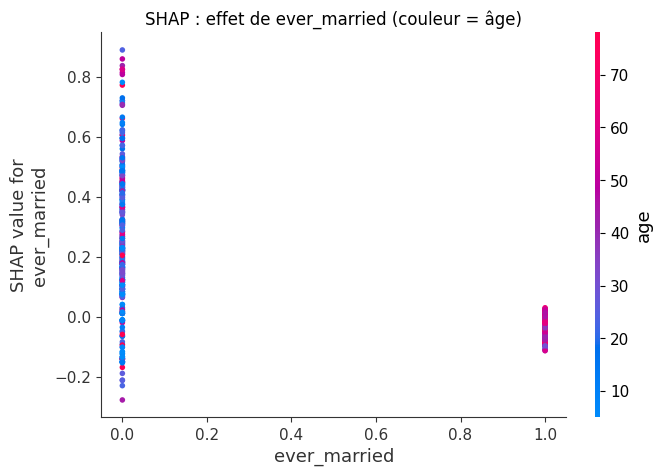

In [40]:
# Effet SHAP moyen de ever_married selon sa valeur
effet = pd.Series(shap_values[:, X_test.columns.get_loc("ever_married")])
print(effet.groupby(X_test["ever_married"].values).mean().rename({0: "jamais marié", 1: "marié"}).round(3))

shap.dependence_plot("ever_married", shap_values, X_test,
                     interaction_index="age", show=False)
plt.title("SHAP : effet de ever_married (couleur = âge)")
plt.show()

**Résultat H10 :  infirmée au sens strict, mais avec une nuance importante.**
- `ever_married` est **5ᵉ selon SHAP** pour XGBoost (2,8 % de l'importance), donc elle est utilisée et entre dans le top 5 → le premier critère n'est pas respecté.
- La LR, elle, l'utilise très peu (13ᵉ sur 17).
- La supprimer ne change presque rien (−0,004 d'AUC pour XGB, +0,0005 pour la LR) → elle n'est **pas indispensable**.

**Observation surprenante :** XGBoost l'utilise **dans le sens inverse** de la statistique brute. Globalement, les personnes mariées ont plus d'AVC (6,6 % contre 1,7 %), mais pour le modèle, **ne jamais avoir été marié augmente le risque** (+0,26 en SHAP).
Une fois l'effet de l'âge pris en compte par le modèle, le statut marital ne joue plus en faveur des mariés. Chez les plus de 60 ans, les personnes jamais mariées ont même plus d'AVC (20 % contre 13 %, étape 2.4).

-> **Interprétation :** le modèle a appris une **corrélation résiduelle**. Elle peut refléter un facteur social réel (isolement, accès aux soins) comme du bruit (peu de patients âgés jamais mariés). L'XAI **révèle** ce que fait le modèle, mais **ne permet pas de conclure à une causalité**. Seul un expert médical peut juger si cette variable doit être conservée.

# 6. Analyse et critique des résultats

## 6.1 Synthèse

| # | Hypothèse | Résultat clé | Verdict |
|---|---|---|---|
| H1 | L'accuracy n'est pas adaptée | Modèle naïf : 95 % d'accuracy, 0 AVC détecté |  Validée |
| H2 | Pondérer les classes aide | Rappel LR : 2 % → 80 % ; précision ≈ 14 % |  Validée |
| H3 | L'absence de BMI est utile | +0,015 d'AUC pour la LR, +0,002 pour XGB |  Partielle |
| H4 | Les arbres battent la LR | LR meilleure (AUC 0,854 vs 0,846 et 0,824) |  Infirmée |
| H5 | Les arbres sont plus rapides | Arbre ≈ 300× plus rapide et meilleur | Validée |
| H6 | Peu de variables suffisent | 4 variables : > 98 % de l'AUC conservée |  Validée |
| H7 | L'âge est n°1 partout | 1er pour les 4 méthodes |  Validée |
| H8 | LR et XGB + SHAP concordent | Spearman = 0,49 (< 0,7) |  Infirmée |
| H9 | SHAP et LIME concordent | 0/5 patients identiques, 1,6/3 en commun |  Infirmée |
| H10 | `ever_married` non utilisée | 5ᵉ selon SHAP, utilisée en sens inverse |  Infirmée |

**Bilan : 5 validées, 1 partielle, 4 infirmées.**

## 6.2 Comparaison avec les prédictions initiales

| # | Prédiction | Résultat | Commentaire |
|---|---|---|---|
| H1 | Vraie | Validée | Attendu : conséquence directe du déséquilibre |
| H2 | Vraie | Validée | Attendu, y compris la baisse de précision |
| H3 | Incertaine | Partiellement validée | L'effet existe mais dépend du modèle |
| H4 | Plutôt fausse | Infirmée | **Bonne intuition** : relations simples + peu d'AVC |
| H5 | Vraie | Validée | Écart encore plus grand que prévu (≈ 300×) |
| H6 | Plutôt vraie | Validée | Confirmé |
| H7 | Plutôt vraie | Validée | Confirmé, mais les rangs suivants divergent |
| H8 | Partiellement vraie | Infirmée | **Sous-estimé** : divergence plus forte que prévu |
| H9 | Partiellement fausse | Infirmée | Confirmé : seul l'âge fait consensus |
| H10 | Incertaine | Infirmée | **Inattendu** : utilisée, et en sens inverse de la statistique brute |

8 prédictions sur 10 étaient cohérentes avec les résultats. Les deux surprises (H8 et H10) concernent l'**explicabilité** : il est plus difficile de prévoir *comment* un modèle raisonne que *combien* il performe.

## 6.3 Quel modèle, quelle métrique, quelle explicabilité ?

**Quel modèle est le meilleur ?**
La **régression logistique pondérée** : meilleure AUC (0,854 en validation croisée), meilleure balanced accuracy (0,777), rappel de 80 %, entraînement quasi instantané et **interprétable par nature**. Une version réduite à 4 variables conserve la même performance (H6).
→ Sur ce jeu de données, **il n'y a pas de compromis entre performance et explicabilité** : le modèle le plus simple est aussi le plus performant (Rudin, 2019).

**Quelle métrique ?**
- L'**accuracy est à proscrire** (H1).
- L'**AUC-ROC** est adaptée pour **comparer des modèles**, car elle est indépendante du seuil.
- Le **rappel** est prioritaire en **dépistage**, puisque rater un AVC est plus grave qu'une fausse alerte. Il doit être présenté avec la **précision**, pour mesurer la charge de fausses alertes.
- La **balanced accuracy** est un bon résumé en une seule valeur.

**Quelle approche d'explicabilité ?**
- **Globale :** les coefficients de la LR suffisent pour le modèle retenu. SHAP reste utile pour les modèles boîte noire.
- **Locale :** SHAP est plus stable et mieux fondé théoriquement que LIME (H9).
- **Aucune méthode ne doit être utilisée seule :** les classements divergent entre modèles et entre méthodes (H7, H8).

## 6.4 Limites et critique

**Limites des données**
- **Origine non documentée :** le jeu de données Kaggle ne précise ni l'hôpital, ni la période, ni le protocole de collecte. Impossible de savoir s'il représente une population réelle.
- **Données transversales :** `stroke` indique un AVC *déjà survenu*, et les mesures (BMI, glycémie) ont pu être prises *après*. Le modèle **décrit** des patients plutôt qu'il ne **prédit** un AVC futur (risque de causalité inversée).
- **Population hétérogène :** enfants et adultes mélangés (l'IMC ne s'interprète pas de la même façon chez l'enfant).
- **Qualité :** BMI jusqu'à 97,6 (valeurs suspectes conservées), 30 % de statut tabagique inconnu.
- **Facteurs de risque absents :** fibrillation auriculaire, cholestérol, antécédents d'AVC, traitements.

**Limites méthodologiques**
- **Seulement 50 AVC dans le test :** un patient mal classé fait varier le rappel de 2 points. La validation croisée atténue ce problème sans le supprimer.
- **Hyperparamètres non optimisés :** XGBoost et le MLP sont probablement désavantagés (H4, H5).
- **Seuil de décision fixé à 0,5 :** un seuil ajusté (par exemple pour atteindre 90 % de rappel) serait plus pertinent cliniquement.
- **Pas de test statistique** sur les écarts entre modèles : les différences d'AUC (≈ 0,01-0,03) sont du même ordre que l'écart-type entre plis.
- **H9 sur 5 patients seulement**, avec une seule graine LIME.
- **Dépendance aux versions :** la Random Forest pondérée donne des résultats différents selon la version de scikit-learn (rappel de 0,22 ici, 0,60 avec une version plus récente). Les versions utilisées sont affichées en début de notebook.

**Limites de l'explicabilité**
- **Expliquer ≠ justifier :** SHAP montre ce que fait le modèle, pas la vérité médicale (H10 : `ever_married` utilisée sans lien causal démontré).
- **Variables corrélées** (âge, `ever_married`, `work_type`) : l'importance se répartit de façon arbitraire entre elles, ce qui fragilise les classements.
- **Biais des méthodes :** l'importance par impureté favorise les variables continues (H6) ; LIME dépend de la discrétisation et de l'échantillonnage (H9).

## 6.5 Conclusion
Ce travail montre que, pour la prédiction de l'AVC sur ce jeu de données :
1. la **préparation des données** (déséquilibre, valeurs manquantes informatives) a plus d'impact que le choix du modèle ;
2. un **modèle simple et interprétable** (régression logistique) est aussi performant que des modèles complexes ;
3. les **méthodes d'explicabilité** s'accordent sur l'essentiel (l'âge), mais **divergent sur les détails**, entre elles comme entre modèles.

-> En contexte médical, l'XAI est un **outil de contrôle** du modèle (détecter un facteur de confusion, une variable inattendue), et non une preuve de sa validité clinique. Celle-ci nécessiterait une validation sur des données externes et prospectives, avec des médecins.

# 7. Bonus

## 7.1 Comment expliquer un modèle et ses prédictions à un médecin ?

**Principes**
1. **Parler le langage clinique, pas celui du ML :** « glycémie 207 mg/dL » plutôt que « avg_glucose_level, SHAP = +0,38 ». Les noms de variables, les unités et les seuils doivent être ceux que le médecin utilise.
2. **Deux niveaux d'explication :**
   - **globale**, présentée une fois lors de la mise en service : sur quoi le modèle s'appuie en général, ses performances et ses limites ;
   - **locale**, pour chaque patient : les 3 facteurs principaux qui augmentent ou diminuent son risque.
3. **Donner un niveau de risque plutôt qu'une probabilité brute :** avec la pondération des classes, les probabilités de notre modèle sont surestimées (non calibrées). Un niveau (faible / modéré / élevé) ou un rang (« plus à risque que 94 % des patients ») est plus honnête.
4. **Annoncer les performances en fréquences naturelles :** « détecte 8 AVC sur 10 ; 1 alerte sur 7 est justifiée », plutôt que « rappel = 0,80, précision = 0,14 ».
5. **Ne citer que des facteurs médicalement interprétables :** un facteur comme « fonctionnaire » ou « déjà marié » doit être signalé comme non causal, voire retiré du modèle (H10).
6. **Proposer des scénarios (contrefactuels) :** « si la glycémie était ramenée sous 140 mg/dL, le niveau de risque passerait de élevé à modéré ». C'est directement exploitable pour la prévention.
7. **Rappeler que c'est une aide à la décision**, qui ne remplace pas le jugement clinique.

**Démonstration** : explication générée automatiquement à partir de la régression logistique (modèle retenu, interprétable par nature : contribution = coefficient × écart du patient à la moyenne).

In [41]:
noms_medicaux = {
    "age": "Âge", "avg_glucose_level": "Glycémie moyenne", "bmi": "IMC",
    "hypertension": "Hypertension", "heart_disease": "Maladie cardiaque",
    "bmi_missing": "IMC non mesuré", "ever_married": "Déjà marié(e)",
    "gender": "Sexe masculin", "Residence_type": "Résidence urbaine",
    "work_type_Not_working": "Enfant / sans activité",
    "work_type_Self-employed": "Travailleur indépendant",
    "work_type_Private": "Salarié du privé", "work_type_Govt_job": "Fonctionnaire",
    "smoking_status_smokes": "Fumeur", "smoking_status_formerly smoked": "Ancien fumeur",
    "smoking_status_never smoked": "Non-fumeur", "smoking_status_Unknown": "Tabagisme inconnu"}
unites = {"age": " ans", "avg_glucose_level": " mg/dL", "bmi": " kg/m²"}

scores_test = modeles["LR"].predict_proba(X_test)[:, 1]

def expliquer_au_medecin(i, n_facteurs=3):
    patient = X_test.iloc[[i]]
    lr = modeles["LR"]
    score = lr.predict_proba(patient)[0, 1]

    # Niveau de risque exprimé par rapport aux autres patients (pas de probabilité brute)
    percentile = (scores_test < score).mean() * 100
    niveau = "ÉLEVÉ" if percentile >= 80 else "MODÉRÉ" if percentile >= 50 else "FAIBLE"

    # Contribution de chaque variable = coefficient x valeur standardisée
    z = lr[0].transform(patient)[0]
    contrib = pd.Series(lr[-1].coef_[0] * z, index=X_test.columns)

    # On ne cite que les variables numériques et les caractéristiques PRÉSENTES chez le patient
    presentes = [v for v in contrib.index if v in unites or patient[v].values[0] == 1]
    contrib = contrib[presentes]
    contrib = contrib[contrib.abs() > 0.05].sort_values(key=abs, ascending=False)

    def decrire(var):
        val = patient[var].values[0]
        if var in unites:
            return f"{noms_medicaux[var]} : {val:.0f}{unites[var]}"
        return f"{noms_medicaux[var]} : {'oui' if val == 1 else 'non'}"

    print(f"=== Patient n°{i} ===")
    print(f"Niveau de risque d'AVC : {niveau} (plus à risque que {percentile:.0f} % des patients)")
    print("\nFacteurs qui AUGMENTENT le risque :")
    for var in contrib[contrib > 0].index[:n_facteurs]:
        print("  -", decrire(var))
    print("Facteurs qui DIMINUENT le risque :")
    for var in contrib[contrib < 0].index[:n_facteurs]:
        print("  -", decrire(var))
    print("\nModèle : régression logistique, AUC = 0,85 ; détecte environ 8 AVC sur 10, "
          "mais seule 1 alerte sur 7 correspond à un AVC réel.")
    print("Aide à la décision : ne remplace pas l'examen clinique.\n")

expliquer_au_medecin(patients[0])                        # un patient ayant eu un AVC
expliquer_au_medecin(np.where(y_test.values == 0)[0][0])  # un patient sans AVC

=== Patient n°33 ===
Niveau de risque d'AVC : ÉLEVÉ (plus à risque que 94 % des patients)

Facteurs qui AUGMENTENT le risque :
  - Âge : 76 ans
  - Glycémie moyenne : 207 mg/dL
  - IMC : 35 kg/m²
Facteurs qui DIMINUENT le risque :
  - Tabagisme inconnu : oui
  - Salarié du privé : oui

Modèle : régression logistique, AUC = 0,85 ; détecte environ 8 AVC sur 10, mais seule 1 alerte sur 7 correspond à un AVC réel.
Aide à la décision : ne remplace pas l'examen clinique.

=== Patient n°0 ===
Niveau de risque d'AVC : FAIBLE (plus à risque que 36 % des patients)

Facteurs qui AUGMENTENT le risque :
  - Hypertension : oui
  - IMC : 36 kg/m²
Facteurs qui DIMINUENT le risque :
  - Âge : 28 ans
  - Fonctionnaire : oui
  - Glycémie moyenne : 84 mg/dL

Modèle : régression logistique, AUC = 0,85 ; détecte environ 8 AVC sur 10, mais seule 1 alerte sur 7 correspond à un AVC réel.
Aide à la décision : ne remplace pas l'examen clinique.



**Analyse de la démonstration :** l'explication est lisible et cohérente médicalement pour les facteurs principaux (âge, glycémie, IMC, hypertension).
Elle révèle aussi ses limites : « Tabagisme inconnu », « Salarié du privé » ou « Fonctionnaire » apparaissent comme protecteurs alors qu'ils n'ont **aucune justification clinique**. Un médecin perdrait confiance face à ces facteurs. C'est un argument pour retenir le **modèle réduit à 4 variables** (H6), plus simple à expliquer et sans variables sociodémographiques ambiguës.

## 7.2 Priorités pour une interface homme-machine (IHM)

| Priorité | Pourquoi | Mise en œuvre |
|---|---|---|
| **1. Intégration au flux de travail** | Un outil qui oblige à ressaisir les données ne sera pas utilisé | Intégration au dossier patient informatisé via HL7 FHIR, calcul automatique à partir des données existantes |
| **2. Lisibilité immédiate** | Le médecin dispose de quelques secondes par patient | Niveau de risque en couleur + 3 facteurs principaux ; détails accessibles sur demande |
| **3. Éviter la fatigue d'alerte** | Avec 1 alerte justifiée sur 7, trop d'alertes conduisent à les ignorer | Seuil ajustable par le service, alertes regroupées, pas de fenêtre bloquante |
| **4. Afficher l'incertitude et les limites** | Le médecin doit savoir quand ne pas faire confiance au modèle | Mention si le patient sort du domaine d'apprentissage (enfant, valeur aberrante, donnée manquante) |
| **5. Le médecin garde le contrôle** | Limiter le biais d'automatisation (suivre la machine sans réfléchir) | Possibilité de rejeter la recommandation en précisant pourquoi ; jamais de décision automatique |
| **6. Explications actionnables** | Une explication doit aider à agir | Scénarios contrefactuels : « si la tension était contrôlée… » |
| **7. Traçabilité** | Responsabilité médico-légale et amélioration continue | Journal des prédictions, versions du modèle et décisions du médecin |
| **8. Conformité réglementaire** | Logiciel d'aide au diagnostic = dispositif médical | Marquage CE (règlement MDR), AI Act (système à haut risque), RGPD (données de santé), recommandations HAS |

**Démarche :** concevoir l'interface **avec** les médecins (conception centrée utilisateur), la tester en conditions réelles et mesurer non seulement la performance du modèle, mais aussi l'**impact sur les décisions médicales**.

## 7.3 Limites de ces approches dans le domaine médical

**1. Corrélation n'est pas causalité**
Les modèles et leurs explications reflètent des corrélations dans les données (H10 : `ever_married`). Une explication SHAP ne dit pas qu'agir sur une variable réduira le risque.

**2. Instabilité et désaccord des explications**
Deux méthodes (SHAP vs LIME, H9) ou deux modèles de performance égale (LR vs XGB, H8) donnent des explications différentes. Laquelle présenter au médecin ? Aucune vérité de référence ne permet de trancher.

**3. Fausse confiance**
Une explication convaincante peut rassurer à tort sur un modèle erroné. Il a même été montré qu'on peut construire des modèles biaisés dont les explications LIME/SHAP paraissent saines (Slack et al., 2020).

**4. Qualité et représentativité des données**
Un modèle entraîné sur une population (ici, origine inconnue) peut se dégrader sur une autre : autre pays, autre hôpital, autre époque. Les biais de collecte (patients jamais mesurés, tabagisme inconnu) se retrouvent dans les prédictions et peuvent créer des **inégalités** entre groupes de patients.

**5. Évaluation insuffisante**
De bonnes métriques sur un jeu de test ne prouvent pas un bénéfice pour le patient. Il faut une validation externe, prospective, puis une évaluation clinique de l'impact réel.

**6. Responsabilité et cadre légal**
En cas d'erreur, qui est responsable : le médecin, l'établissement, le fabricant ? Le RGPD et l'AI Act imposent transparence et contrôle humain, mais l'explicabilité exigée reste mal définie.

**7. Coût cognitif**
Ajouter des explications à chaque prédiction alourdit la charge de travail. Trop d'information peut nuire à la décision autant que trop peu.

**Conclusion :** l'XAI est un **outil indispensable pour auditer** un modèle et instaurer la confiance, mais elle ne remplace ni la validation clinique, ni le jugement médical.